In [21]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pandas as pd
import numpy as np
from safetensors.torch import load_file

# Add parent directory to path to import utils if needed
sys.path.append(str(Path.cwd().parent))

# Configuration
RESULTS_DIR = Path("../results/cocoqa_img_vs_txt/similarities")
# Base path for ID measures (results directory)
ID_RESULTS_BASE = Path("../results")
PLOTS_DIR = Path("../plots/multimodality_similarity")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Pretrained": "llava-v1.5-7b-pretrained-lbasile",
    "Finetuned": "llava-1.5-7b-hf"
}

# Mapping for ID data folder names (different from similarity filenames)
ID_MODEL_NAMES = {
    "Pretrained": "llava-v1.5-mlp2x-336px-pretrain-vicuna-7b-v1.5",
    "Finetuned": "llava-1.5-7b-hf"
}

MEASURES = {
    "neighborhood_overlap": "Neighborhood Overlap",
    "linear_cka": "Linear CKA",
    "distance_correlation": "Distance Correlation"
}

In [22]:
def load_data(model_name, measure_key):
    filename = f"{model_name}_{measure_key}.safetensors"
    path = RESULTS_DIR / filename
    try:
        data = load_file(str(path))
        # The key inside safetensors matches the measure name (e.g. "neighborhood_overlap")
        tensor = data[measure_key]
        return tensor.cpu().numpy()
    except Exception as e:
        print(f"Error loading {filename}: {e}")
        return None

def load_id_data(dataset_key, model_key):
    """
    Load Intrinsic Dimension data.
    dataset_key: 'cocoqa_img' or 'cocoqa_txt'
    model_key: 'Pretrained' or 'Finetuned'
    """
    model_dir = ID_MODEL_NAMES[model_key]
    # Verify path construction
    # e.g. ../results/cocoqa_img/models_data_measures/llava-1.5-7b-hf/id_16_100_output_layer_last.safetensors
    path = ID_RESULTS_BASE / dataset_key / "models_data_measures" / model_dir / "id_16_100_output_layer_last.safetensors"
    
    try:
        data = load_file(str(path))
        tensor = data["layers_intrinsic_dimension"]
        return tensor.cpu().numpy()
    except Exception as e:
        print(f"Error loading ID data from {path}: {e}")
        return None

def plot_measure_comparison(measure_key, measure_title):
    # Load data for both models (Similarity + ID)
    sim_pm = load_data(MODELS["Pretrained"], measure_key)
    sim_fm = load_data(MODELS["Finetuned"], measure_key)
    
    # ID Data: Image (Top/X) corresponds to cocoqa_img
    id_img_pm = load_id_data("cocoqa_img", "Pretrained")
    id_img_fm = load_id_data("cocoqa_img", "Finetuned")
    
    # ID Data: Text (Right/Y) corresponds to cocoqa_txt
    id_txt_pm = load_id_data("cocoqa_txt", "Pretrained")
    id_txt_fm = load_id_data("cocoqa_txt", "Finetuned")

    if any(x is None for x in [sim_pm, sim_fm, id_img_pm, id_txt_pm]):
        print(f"Skipping plot for {measure_title} due to missing data.")
        return

    # Setup figure
    fig = plt.figure(figsize=(20, 10))
    
    # Outer Grid: Top Area (Plots), Bottom Area (Colorbar)
    gs_outer = gridspec.GridSpec(2, 1, height_ratios=[1, 0.08], hspace=0.25)
    
    # Top Area: Split into Left (Pretrained) and Right (Finetuned)
    gs_main = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[0], wspace=0.2)
    
    models_list = [
        ("Pretrained", sim_pm, id_img_pm, id_txt_pm),
        ("Finetuned", sim_fm, id_img_fm, id_txt_fm)
    ]
    
    heatmap_axes = []
    
    for idx, (model_label, sim_data, id_img, id_txt) in enumerate(models_list):
        # Inner Grid for each model: 2x2
        # R0: [Top Plot, Empty]
        # R1: [Heatmap, Right Plot]
        gs_inner = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs_main[idx],
                                                    width_ratios=[6, 1], height_ratios=[1, 6],
                                                    wspace=0.03, hspace=0.03)
        
        ax_top = fig.add_subplot(gs_inner[0, 0])
        ax_main = fig.add_subplot(gs_inner[1, 0])
        ax_right = fig.add_subplot(gs_inner[1, 1])
        
        # Share axes
        ax_top.sharex(ax_main)
        ax_right.sharey(ax_main)
        
        # 1. Main Heatmap
        sns.heatmap(
            sim_data,
            ax=ax_main,
            cmap="viridis",
            vmin=0, vmax=1,
            square=False, # Let grid control aspect
            cbar=False
        )
        heatmap_axes.append(ax_main)
        
        # Centers for 1D plots
        x_centers = np.arange(len(id_img)) + 0.5
        y_centers = np.arange(len(id_txt)) + 0.5
        
        # 2. Top Plot (Image ID)
        ax_top.plot(x_centers, id_img, color='#377eb8', lw=2) # Blue-ish
        ax_top.fill_between(x_centers, id_img, color='#377eb8', alpha=0.3)
        
        # Display ID axis (Y-axis) and labels
        sns.despine(ax=ax_top, bottom=True, left=False)
        ax_top.tick_params(bottom=False, labelbottom=False)
        ax_top.tick_params(axis='y', labelsize=8)
        ax_top.set_ylabel("ID", fontsize=9, rotation=0, labelpad=15)
        
        # 3. Right Plot (Text ID)
        ax_right.plot(id_txt, y_centers, color='#e41a1c', lw=2) # Red-ish
        ax_right.fill_betweenx(y_centers, id_txt, color='#e41a1c', alpha=0.3)
        
        # Display ID axis (X-axis) and labels
        sns.despine(ax=ax_right, left=True, bottom=False)
        ax_right.tick_params(left=False, labelleft=False)
        ax_right.tick_params(axis='x', labelsize=8)
        ax_right.set_xlabel("ID", fontsize=9)
        
        # Formatting Main Axis
        ax_main.set_xlabel("Image Layers", fontsize=13, labelpad=8)
        ax_main.set_ylabel("Text Layers", fontsize=13, labelpad=8)
        ax_main.invert_yaxis() # 0 at bottom
        
        # Ticks
        num_layers = sim_data.shape[0]
        ticks = range(0, num_layers, 5)
        ax_main.set_xticks([t + 0.5 for t in ticks])
        ax_main.set_xticklabels(ticks, fontsize=11)
        ax_main.set_yticks([t + 0.5 for t in ticks])
        ax_main.set_yticklabels(ticks, fontsize=11)
        
        # Add model label using text or title on top ax
        ax_top.set_title(f"{model_label}", fontsize=18, pad=10, fontweight='medium')

    # Colorbar
    cax = fig.add_subplot(gs_outer[1])
    # Create a dummy mappable or use the last heatmap's mappable
    mappable = heatmap_axes[-1].collections[0]
    plt.colorbar(mappable, cax=cax, orientation='horizontal', label=measure_title)
    
    # Adjust layout
    fig.suptitle(f"{measure_title}: Text vs Image Modality Similarity",#\n(with Intrinsic Dimension Marginals)",
                 fontsize=22, fontweight='bold', y=0.98)
    
    # Save
    save_path = PLOTS_DIR / f"multimodality_{measure_key}_comparison_with_id.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor='white')
    print(f"Saved plot to {save_path}")
    plt.show()

Saved plot to ../plots/multimodality_similarity/multimodality_neighborhood_overlap_comparison_with_id.png


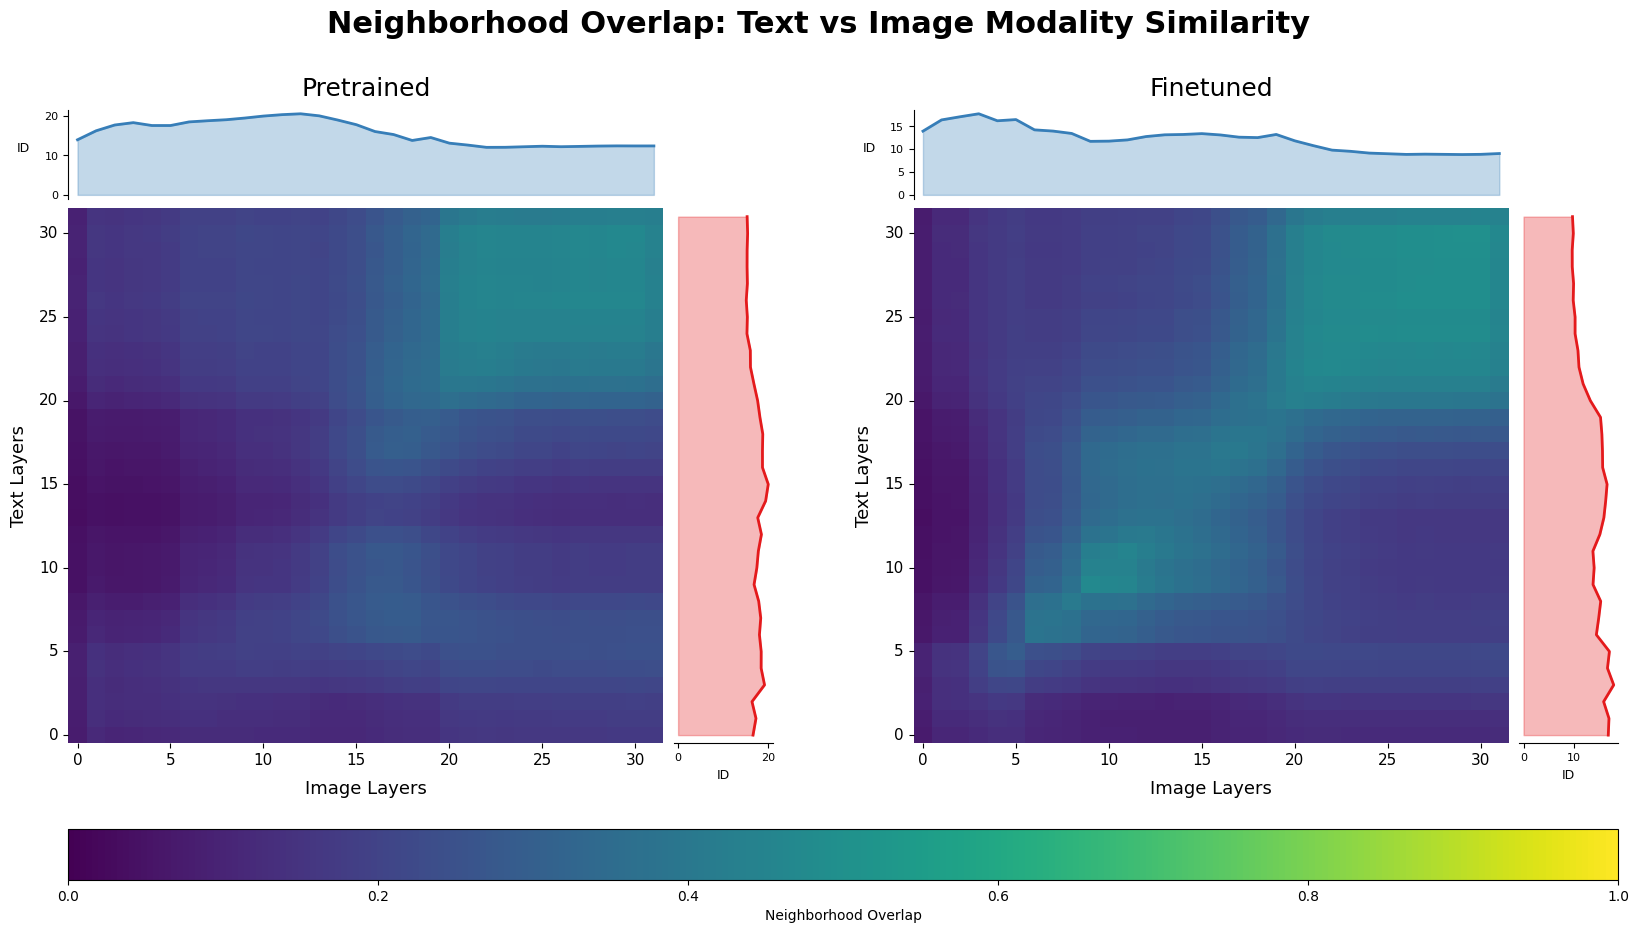

Saved plot to ../plots/multimodality_similarity/multimodality_linear_cka_comparison_with_id.png


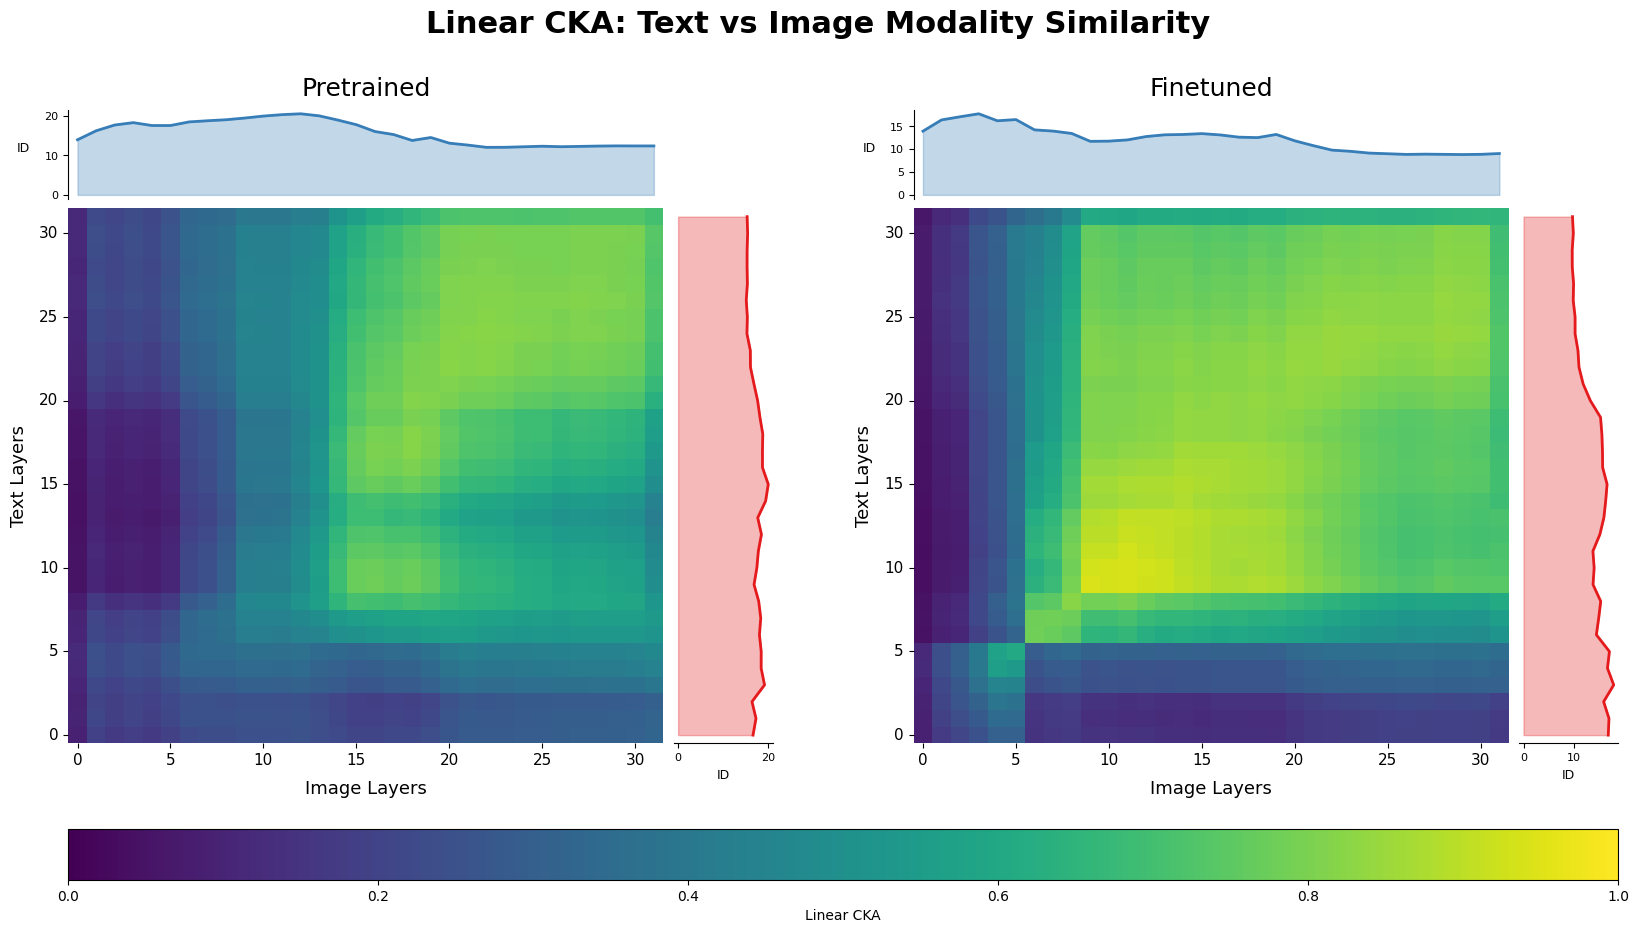

Saved plot to ../plots/multimodality_similarity/multimodality_distance_correlation_comparison_with_id.png


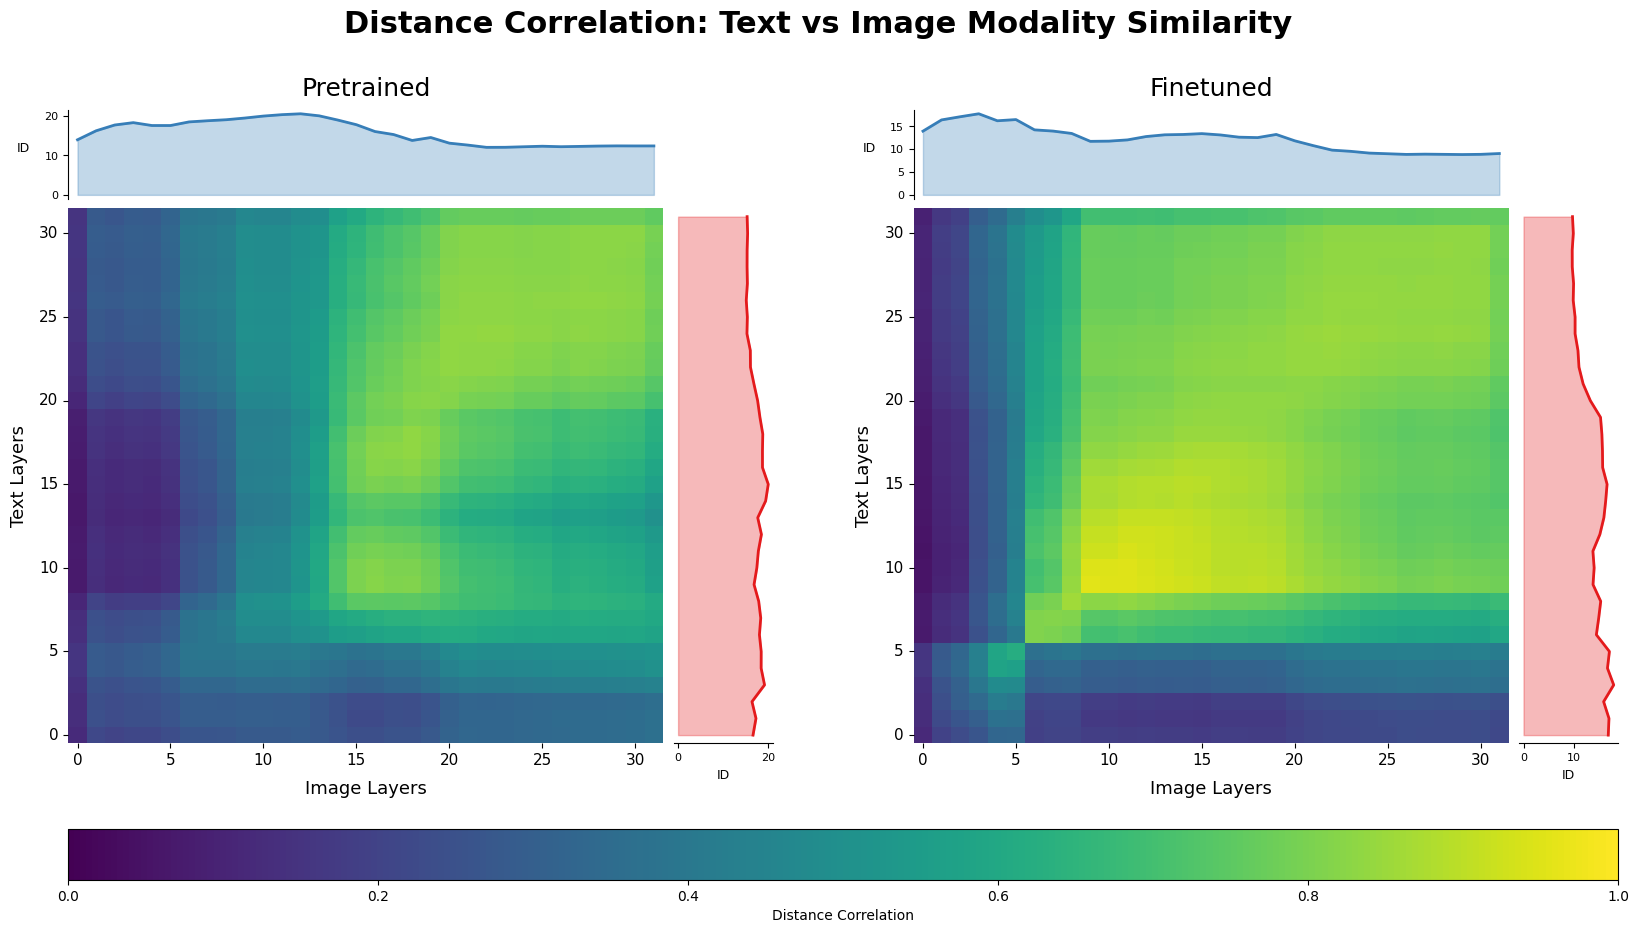

In [23]:
# Generate plots for all measures
for key, title in MEASURES.items():
    plot_measure_comparison(key, title)